# Test klasyfikatora (Pjoter) — accuracy i macierze pomyłek vs 3 typy szumu

Pjoter zrobił `StateClassifierCNN`, nie rekonstruktor — ten notebook ewaluuje klasyfikację (nie fidelity)
na trzech sweepach (`data/sweep`, `data/sweep_dephase`, `data/sweep_gauss`), licząc accuracy i macierz
pomyłek **osobno dla każdego poziomu szumu**, żeby zobaczyć nie tylko *gdzie* model się wykłada, ale *na
jakie klasy* najpierw traci.

**Uruchamiaj z katalogu `qsdl/cnn/`** (tak jak `cnn.ipynb`) — importy `data`, `classifier`, `evaluation`
zakładają, że to jest working directory.

In [1]:
from pathlib import Path
import json

import h5py
import numpy as np
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from data import WignerDataset
from classifier import StateClassifierCNNv2
from evaluation import evaluate

## Konfiguracja

`MODEL_PATH` — checkpoint od Pjotra. Foldery sweepów jak poprzednio — notebook sam znajdzie plik `.h5`
w każdym z nich.

**Jeśli właśnie poprawiłeś `noise.py` (kalibracja gaussa) — `data/sweep_gauss` trzeba wygenerować od
nowa, stary plik ma zapisane sigmy z zepsutej, za łagodnej skali.**

In [2]:
root = Path.cwd().parent.parent

MODEL_PATH = root / "models" / "v2_train_noisy_19999.pt"

SWEEP_DIRS = {
    "photon_loss": root / "scripts" / "data" / "sweep",
    "dephase":     root / "scripts" /"data" / "sweep_dephase",
    "gauss":       root / "scripts" /"data" / "sweep_gauss",
}

LABELS = ("fock", "coherent", "vacuum", "thermal", "cat", "gkp", "binomial")
BATCH_SIZE = 64

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"device: {device}")
print(f"model:  {MODEL_PATH}  (istnieje: {MODEL_PATH.exists()})")
for name, d in SWEEP_DIRS.items():
    print(f"{name:12s}: {d}  (istnieje: {d.exists()})")

device: cpu
model:  /home/sebas/fork/qsdl/models/v2_train_noisy_19999.pt  (istnieje: True)
photon_loss : /home/sebas/fork/qsdl/scripts/data/sweep  (istnieje: True)
dephase     : /home/sebas/fork/qsdl/scripts/data/sweep_dephase  (istnieje: True)
gauss       : /home/sebas/fork/qsdl/scripts/data/sweep_gauss  (istnieje: True)


## Wczytanie modelu

`StateClassifierCNNv2` (nie oryginalny `StateClassifierCNN`, ani `StateReconstructor`) — to architektura
odtworzona wprost z kształtów tensorów w checkpoincie Pjotra, zweryfikowana `load_state_dict(strict=True)`
→ "All keys matched successfully". Powinno wczytać się bez błędu.

In [3]:
model = StateClassifierCNNv2().to(device)
state_dict = torch.load(MODEL_PATH, map_location=device, weights_only=True)

try:
    model.load_state_dict(state_dict)
    print("Wagi wczytane poprawnie.")
except RuntimeError as e:
    print("BLAD wczytywania wag -- sprawdz czy MODEL_PATH wskazuje na v2_train_noisy_19999.pt")
    print("(StateClassifierCNNv2 jest dopasowana dokladnie pod ten checkpoint):\n")
    print(e)
    raise

model.eval()

Wagi wczytane poprawnie.


StateClassifierCNNv2(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bi

## Funkcje pomocnicze

- `find_h5` — znajduje plik `.h5` w folderze sweepu
- `get_noise_pct` — czyta poziom szumu z metadanych (fallback na `photonL` dla starszych zbiorów)
- `group_indices_by_level` — grupuje indeksy próbek wg poziomu szumu
- `evaluate_sweep` — dla każdego poziomu buduje osobny `WignerDataset`/`DataLoader` i woła **istniejącą**
  `evaluate()` z `evaluation.py` (accuracy + confusion matrix), bez duplikowania logiki

In [4]:
def find_h5(dir_path: Path) -> Path:
    dir_path = Path(dir_path)
    candidates = sorted(dir_path.glob("*.h5"))
    if len(candidates) == 0:
        raise FileNotFoundError(f"Brak plikow .h5 w {dir_path}")
    if len(candidates) > 1:
        print(f"UWAGA: kilka plikow h5 w {dir_path}, biore pierwszy: {candidates[0].name}")
        print(f"  wszystkie: {[c.name for c in candidates]}")
    return candidates[0]


def get_noise_pct(meta: dict) -> int:
    if "noise_level_pct" in meta:
        return int(meta["noise_level_pct"])
    if "photonL" in meta:
        return round((1.0 - meta["photonL"]) * 100)
    raise KeyError("Brak informacji o poziomie szumu w metadanych tej probki")


def group_indices_by_level(h5_path: Path) -> dict:
    with h5py.File(h5_path, "r") as f:
        meta_all = [json.loads(m) for m in f["metadata"][:]]
    by_level = {}
    for i, m in enumerate(meta_all):
        pct = get_noise_pct(m)
        by_level.setdefault(pct, []).append(i)
    return by_level


def evaluate_sweep(h5_path: Path, model, device, batch_size=64, desc=""):
    by_level = group_indices_by_level(h5_path)
    results = []
    cms = {}
    for pct in tqdm(sorted(by_level), desc=f"Ewaluacja {desc}"):
        idxs = by_level[pct]
        ds = WignerDataset(h5_path, indices=idxs)
        loader = DataLoader(ds, batch_size=batch_size, shuffle=False)
        acc, cm = evaluate(model, loader, device)
        results.append({"loss_pct": pct, "accuracy": float(acc), "n_samples": len(idxs)})
        cms[pct] = cm
    return results, cms

## Ewaluacja wszystkich trzech sweepów

In [5]:
results_by_type = {}
cms_by_type = {}

for noise_type, dir_path in SWEEP_DIRS.items():
    h5_path = find_h5(dir_path)
    print(f"\n=== {noise_type}: {h5_path.name} ===")
    results, cms = evaluate_sweep(h5_path, model, device, batch_size=BATCH_SIZE, desc=noise_type)
    results_by_type[noise_type] = results
    cms_by_type[noise_type] = cms
    for r in results:
        print(f"  {r['loss_pct']}% | accuracy = {r['accuracy']:.4f}  (n={r['n_samples']})")

UWAGA: kilka plikow h5 w /home/sebas/fork/qsdl/scripts/data/sweep, biore pierwszy: train_noisy_14000.h5
  wszystkie: ['train_noisy_14000.h5', 'train_noisy_2800.h5']

=== photon_loss: train_noisy_14000.h5 ===


Ewaluacja photon_loss:   0%|          | 0/17 [00:00<?, ?it/s]

  20% | accuracy = 1.0000  (n=811)
  25% | accuracy = 1.0000  (n=801)
  30% | accuracy = 1.0000  (n=834)
  35% | accuracy = 1.0000  (n=862)
  40% | accuracy = 1.0000  (n=790)
  45% | accuracy = 1.0000  (n=862)
  50% | accuracy = 1.0000  (n=785)
  55% | accuracy = 0.9988  (n=855)
  60% | accuracy = 0.9479  (n=883)
  65% | accuracy = 0.8226  (n=806)
  70% | accuracy = 0.6429  (n=829)
  75% | accuracy = 0.5098  (n=816)
  80% | accuracy = 0.5023  (n=852)
  85% | accuracy = 0.4434  (n=821)
  90% | accuracy = 0.3625  (n=789)
  95% | accuracy = 0.2422  (n=801)
  100% | accuracy = 0.1370  (n=803)

=== dephase: train_noisy_14000.h5 ===


Ewaluacja dephase:   0%|          | 0/21 [00:00<?, ?it/s]

  0% | accuracy = 1.0000  (n=641)
  5% | accuracy = 0.8529  (n=639)
  10% | accuracy = 0.7515  (n=676)
  15% | accuracy = 0.7890  (n=692)
  20% | accuracy = 0.7898  (n=685)
  25% | accuracy = 0.7896  (n=656)
  30% | accuracy = 0.8023  (n=688)
  35% | accuracy = 0.7657  (n=653)
  40% | accuracy = 0.7523  (n=646)
  45% | accuracy = 0.7955  (n=719)
  50% | accuracy = 0.7831  (n=710)
  55% | accuracy = 0.7711  (n=651)
  60% | accuracy = 0.7518  (n=697)
  65% | accuracy = 0.8192  (n=625)
  70% | accuracy = 0.7938  (n=679)
  75% | accuracy = 0.7446  (n=689)
  80% | accuracy = 0.7888  (n=677)
  85% | accuracy = 0.8093  (n=624)
  90% | accuracy = 0.7853  (n=652)
  95% | accuracy = 0.7711  (n=629)
  100% | accuracy = 0.7381  (n=672)
UWAGA: kilka plikow h5 w /home/sebas/fork/qsdl/scripts/data/sweep_gauss, biore pierwszy: train_noisy_14000.h5
  wszystkie: ['train_noisy_14000.h5', 'train_noisy_2000_copy.h5']

=== gauss: train_noisy_14000.h5 ===


Ewaluacja gauss:   0%|          | 0/21 [00:00<?, ?it/s]

  0% | accuracy = 1.0000  (n=641)
  5% | accuracy = 1.0000  (n=639)
  10% | accuracy = 1.0000  (n=676)
  15% | accuracy = 1.0000  (n=692)
  20% | accuracy = 1.0000  (n=685)
  25% | accuracy = 1.0000  (n=656)
  30% | accuracy = 1.0000  (n=688)
  35% | accuracy = 1.0000  (n=653)
  40% | accuracy = 1.0000  (n=646)
  45% | accuracy = 1.0000  (n=719)
  50% | accuracy = 1.0000  (n=710)
  55% | accuracy = 1.0000  (n=651)
  60% | accuracy = 1.0000  (n=697)
  65% | accuracy = 1.0000  (n=625)
  70% | accuracy = 1.0000  (n=679)
  75% | accuracy = 1.0000  (n=689)
  80% | accuracy = 1.0000  (n=677)
  85% | accuracy = 1.0000  (n=624)
  90% | accuracy = 1.0000  (n=652)
  95% | accuracy = 1.0000  (n=629)
  100% | accuracy = 1.0000  (n=672)


## Zapis wyników (accuracy) do JSON

In [6]:
results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

for noise_type, results in results_by_type.items():
    out_path = results_dir / f"v2_classifier_accuracy_{noise_type}.json"
    with open(out_path, "w") as f:
        json.dump(results, f, indent=2)
    print(f"Zapisano -> {out_path}")

Zapisano -> /home/sebas/fork/qsdl/results/v2_classifier_accuracy_photon_loss.json
Zapisano -> /home/sebas/fork/qsdl/results/v2_classifier_accuracy_dephase.json
Zapisano -> /home/sebas/fork/qsdl/results/v2_classifier_accuracy_gauss.json


## Zapis macierzy pomyłek (każdy poziom, każdy typ szumu)

Zapisuje **wszystkie** macierze na dysk (PNG do oglądania + `.npy` do dalszej analizy). Żeby nie zalać
notebooka 63 wykresami (21 poziomów x 3 typy), inline pokazujemy tylko 0% / 50% / 100% per typ — reszta
czeka w `results/confusion_matrices/`.

In [7]:
def plot_cm(cm, tit, filename=None, show=True):
    names = LABELS
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax.set(
        xticks=np.arange(len(names)), yticks=np.arange(len(names)),
        xticklabels=names, yticklabels=names,
        ylabel="Prawdziwa klasa", xlabel="Predykcja", title=tit,
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    thresh = cm.max() / 2.0 if cm.max() > 0 else 1
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > thresh else "black", fontsize=9)

    fig.tight_layout()
    if filename:
        fig.savefig(filename, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)

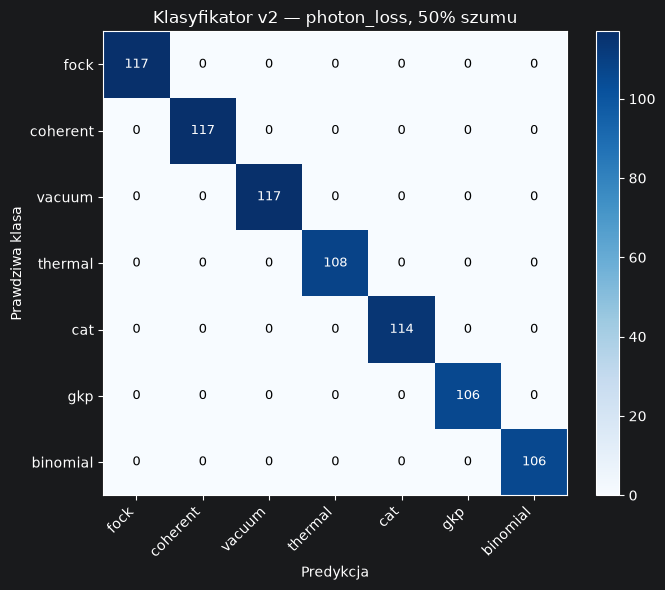

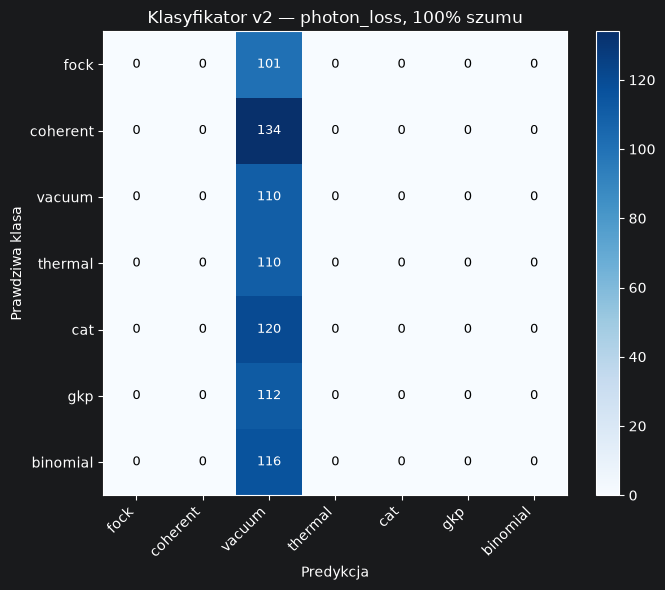

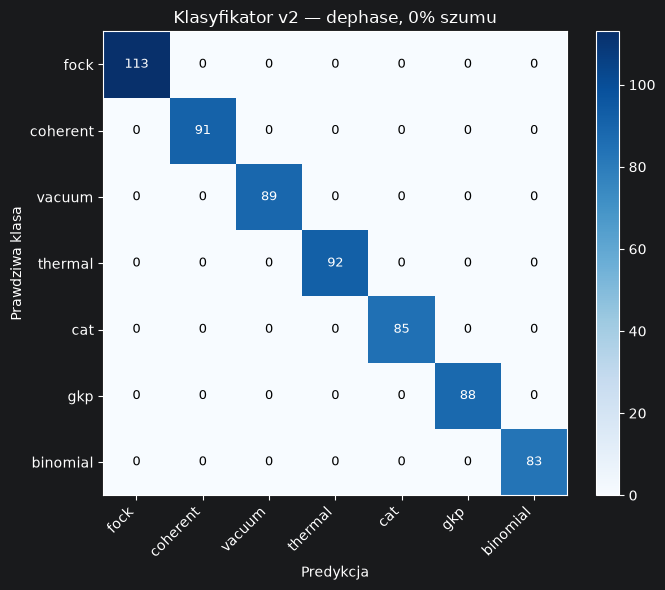

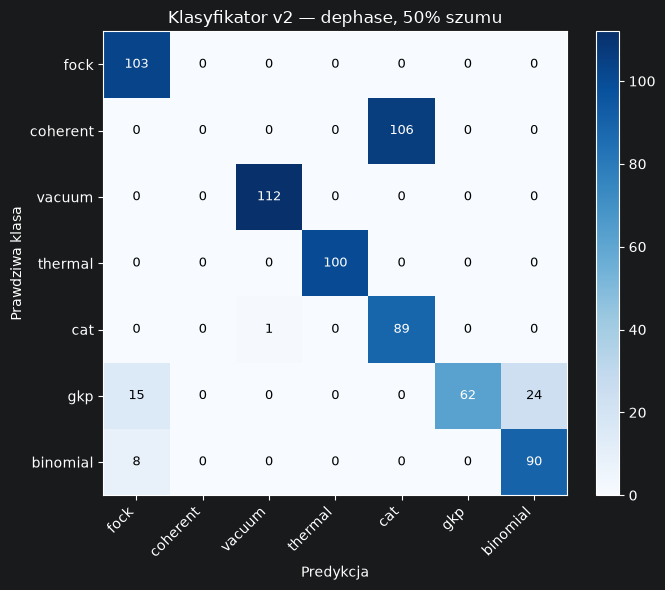

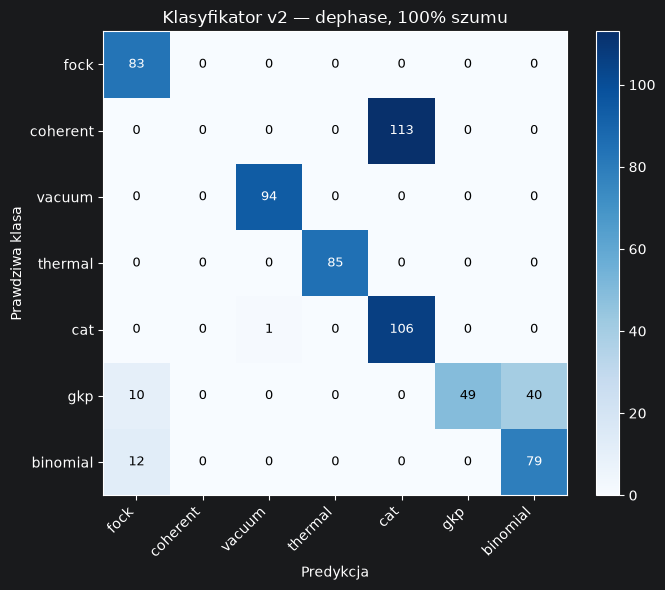

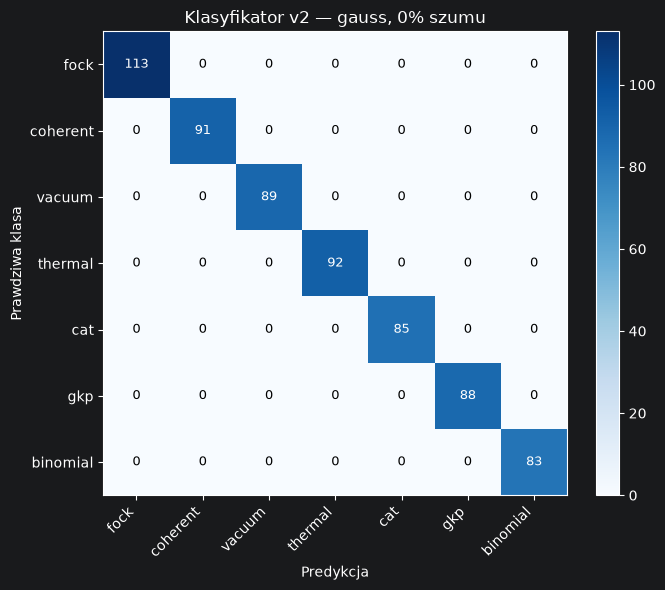

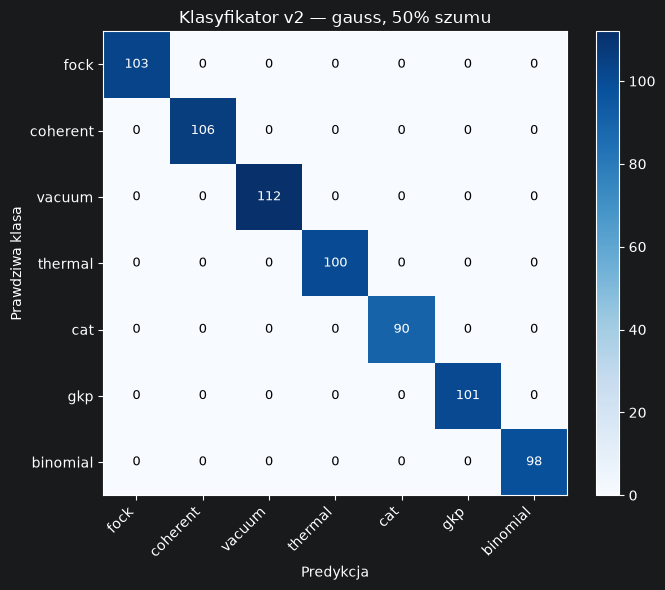

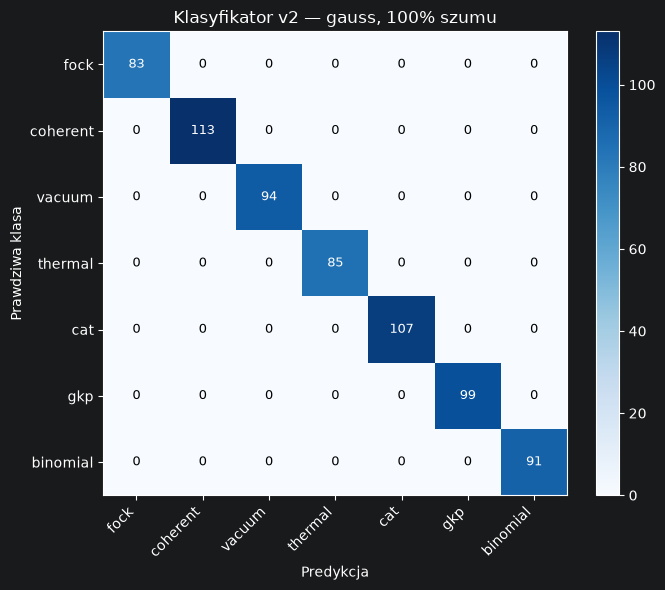

Wszystkie macierze pomylek zapisane w -> /home/sebas/fork/qsdl/results/confusion_matrices


In [8]:
cm_dir = results_dir / "confusion_matrices"
SHOW_LEVELS = {0, 50, 100}

for noise_type, cms in cms_by_type.items():
    type_dir = cm_dir / noise_type
    type_dir.mkdir(parents=True, exist_ok=True)

    for pct, cm in cms.items():
        np.save(type_dir / f"cm_{pct:03d}pct.npy", cm)
        show = pct in SHOW_LEVELS
        plot_cm(
            cm,
            tit=f"Klasyfikator v2 — {noise_type}, {pct}% szumu",
            filename=type_dir / f"cm_{pct:03d}pct.png",
            show=show,
        )

print(f"Wszystkie macierze pomylek zapisane w -> {cm_dir}")

## Accuracy vs poziom szumu — 3 osobne wykresy

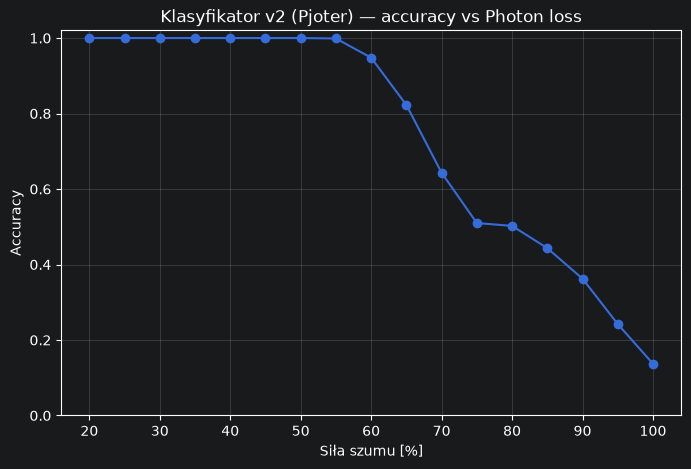

Zapisano wykres -> /home/sebas/fork/qsdl/figures/v2_classifier_accuracy_photon_loss.png


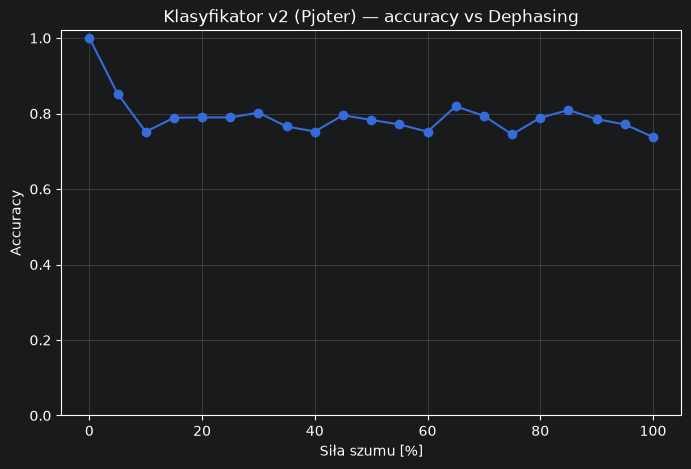

Zapisano wykres -> /home/sebas/fork/qsdl/figures/v2_classifier_accuracy_dephase.png


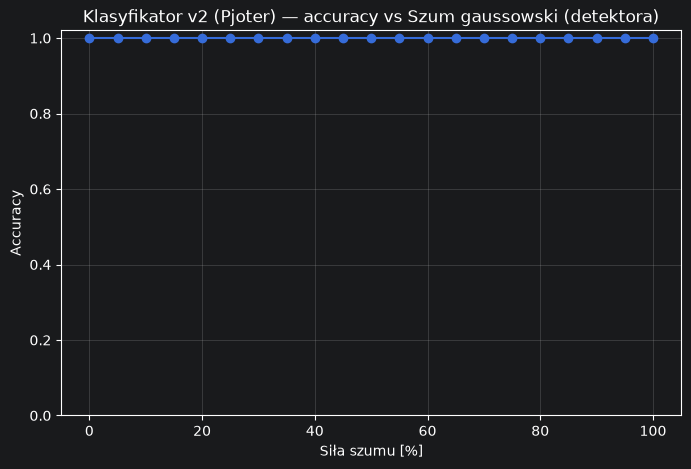

Zapisano wykres -> /home/sebas/fork/qsdl/figures/v2_classifier_accuracy_gauss.png


In [9]:
TITLES = {
    "photon_loss": "Photon loss",
    "dephase": "Dephasing",
    "gauss": "Szum gaussowski (detektora)",
}

figures_dir = root / "figures"
figures_dir.mkdir(exist_ok=True)

for noise_type, results in results_by_type.items():
    xs = [r["loss_pct"] for r in results]
    ys = [r["accuracy"] for r in results]

    plt.figure(figsize=(8, 5))
    plt.plot(xs, ys, marker="o")
    plt.xlabel("Siła szumu [%]")
    plt.ylabel("Accuracy")
    plt.title(f"Klasyfikator v2 (Pjoter) — accuracy vs {TITLES[noise_type]}")
    plt.grid(alpha=0.3)
    plt.ylim(0, 1.02)

    fig_path = figures_dir / f"v2_classifier_accuracy_{noise_type}.png"
    plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Zapisano wykres -> {fig_path}")

## Bonus: porównanie wszystkich trzech na jednym wykresie

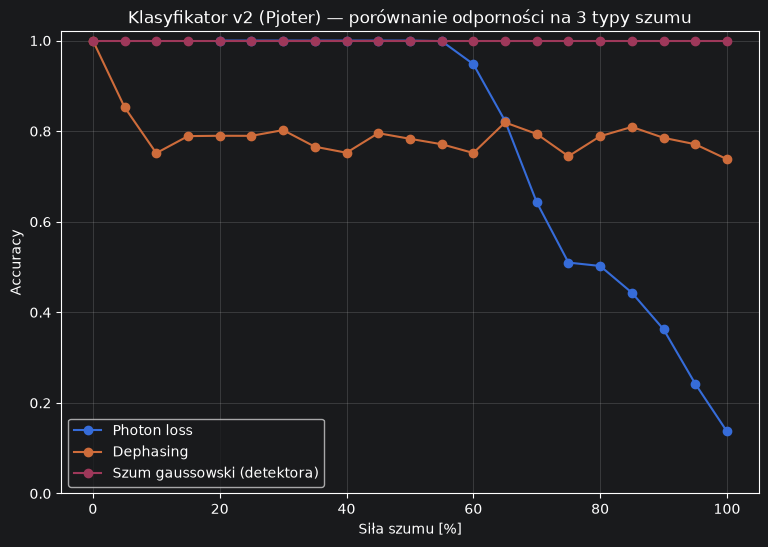

In [10]:
plt.figure(figsize=(9, 6))
for noise_type, results in results_by_type.items():
    xs = [r["loss_pct"] for r in results]
    ys = [r["accuracy"] for r in results]
    plt.plot(xs, ys, marker="o", label=TITLES[noise_type])

plt.xlabel("Siła szumu [%]")
plt.ylabel("Accuracy")
plt.title("Klasyfikator v2 (Pjoter) — porównanie odporności na 3 typy szumu")
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0, 1.02)
plt.savefig(figures_dir / "v2_classifier_accuracy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Uwaga do interpretacji dephasingu

`fock`, `vacuum`, `thermal` są diagonalne w bazie Focka — dephasing matematycznie na nie **nie działa**
(macierz gęstości nie ma koherencji poza-diagonalnych do zniszczenia). Jeśli krzywa dephasingu wygląda
"słabo", sprawdź macierze pomyłek przy wysokim % — spodziewaj się, że błędy koncentrują się w
`coherent`/`cat`/`gkp`/`binomial`, a te trzy pierwsze klasy zostają praktycznie nietknięte niezależnie
od poziomu szumu. To fizyka, nie bug.